# SWYNEX Task 3: Machine Learning Model Improvement

## Objective

The objective of this project is to improve and validate a machine learning classification model using suitable hyperparameter tuning and cross-validation techniques.

The Breast Cancer Wisconsin dataset is used to compare the baseline Logistic Regression model with an optimized version. Model performance is evaluated using accuracy, precision, recall, F1-score, ROC-AUC, and a confusion matrix.

The results are compared with the previous model evaluation to determine whether the optimization improves performance.

In [1]:

# Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    StratifiedKFold
)

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:
# Load the Breast Cancer Wisconsin dataset
data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="target")

print("Dataset loaded successfully!")
print("Number of samples:", X.shape[0])
print("Number of features:", X.shape[1])
print("\nTarget classes:")
print(data.target_names)

print("\nFirst five rows:")
display(X.head())

Dataset loaded successfully!
Number of samples: 569
Number of features: 30

Target classes:
['malignant' 'benign']

First five rows:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [3]:
# Dataset source and data quality analysis

print("DATASET INFORMATION")
print("-" * 40)
print("Dataset: Breast Cancer Wisconsin (Diagnostic)")
print("Source: Scikit-learn built-in dataset")
print("Data type: Real-world diagnostic dataset")
print("Total records:", X.shape[0])
print("Total features:", X.shape[1])

print("\nDATA QUALITY CHECK")
print("-" * 40)
print("Missing values:", X.isnull().sum().sum())
print("Duplicate rows:", X.duplicated().sum())
print("Infinite values:", np.isinf(X.to_numpy()).sum())

print("\nMISSING VALUES PER FEATURE")
missing_summary = X.isnull().sum()
print(missing_summary[missing_summary > 0])

print("\nCLASS DISTRIBUTION")
print(y.value_counts().rename(index={
    0: "malignant",
    1: "benign"
}))

DATASET INFORMATION
----------------------------------------
Dataset: Breast Cancer Wisconsin (Diagnostic)
Source: Scikit-learn built-in dataset
Data type: Real-world diagnostic dataset
Total records: 569
Total features: 30

DATA QUALITY CHECK
----------------------------------------
Missing values: 0
Duplicate rows: 0
Infinite values: 0

MISSING VALUES PER FEATURE
Series([], dtype: int64)

CLASS DISTRIBUTION
target
benign       357
malignant    212
Name: count, dtype: int64


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 455
Testing samples: 114


In [5]:
baseline_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=10000, random_state=42))
])

baseline_model.fit(X_train, y_train)

baseline_predictions = baseline_model.predict(X_test)
baseline_probabilities = baseline_model.predict_proba(X_test)[:, 1]

baseline_results = {
    "Model": "Baseline Logistic Regression",
    "Accuracy": accuracy_score(y_test, baseline_predictions),
    "Precision": precision_score(y_test, baseline_predictions),
    "Recall": recall_score(y_test, baseline_predictions),
    "F1-Score": f1_score(y_test, baseline_predictions),
    "ROC-AUC": roc_auc_score(y_test, baseline_probabilities)
}

print("Baseline model evaluation:")
display(pd.DataFrame([baseline_results]).round(4))

Baseline model evaluation:


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Baseline Logistic Regression,0.9825,0.9861,0.9861,0.9861,0.9954


BASELINE MODEL RESULTS
Accuracy: 0.9825
Precision: 0.9861
Recall: 0.9861
F1-Score: 0.9861
ROC-AUC: 0.9954

Classification Report:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



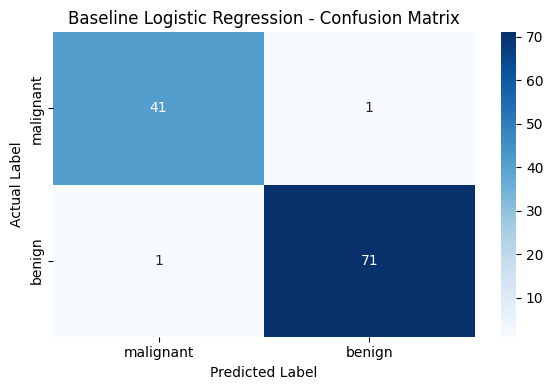

In [6]:
# Baseline Logistic Regression evaluation

print("BASELINE MODEL RESULTS")
print("=" * 45)

for metric, value in baseline_results.items():
    if metric != "Model":
        print(f"{metric}: {value:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    baseline_predictions,
    target_names=data.target_names
))

cm = confusion_matrix(y_test, baseline_predictions)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=data.target_names,
    yticklabels=data.target_names
)
plt.title("Baseline Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

In [7]:
# Hyperparameter tuning using 5-fold cross-validation

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=10000,
        random_state=42
    ))
])

param_grid = {
    "model__C": [0.001, 0.01, 0.1, 1, 10, 100],
    "model__solver": ["liblinear", "lbfgs"]
}

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    return_train_score=True
)

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Mean Cross-Validation Macro F1-Score:")
print(round(grid_search.best_score_, 4))

Best Parameters:
{'model__C': 0.1, 'model__solver': 'liblinear'}

Best Mean Cross-Validation Macro F1-Score:
0.9811


In [8]:
# Evaluate the best tuned model on the test set

best_model = grid_search.best_estimator_

tuned_predictions = best_model.predict(X_test)
tuned_probabilities = best_model.predict_proba(X_test)[:, 1]

tuned_results = {
    "Model": "Tuned Logistic Regression",
    "Accuracy": accuracy_score(y_test, tuned_predictions),
    "Precision": precision_score(y_test, tuned_predictions),
    "Recall": recall_score(y_test, tuned_predictions),
    "F1-Score": f1_score(y_test, tuned_predictions),
    "ROC-AUC": roc_auc_score(y_test, tuned_probabilities)
}

print("TUNED MODEL RESULTS")
print("=" * 40)

display(pd.DataFrame([tuned_results]).round(4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    tuned_predictions,
    target_names=data.target_names
))

TUNED MODEL RESULTS


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Tuned Logistic Regression,0.9825,0.9861,0.9861,0.9861,0.996



Classification Report:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



BASELINE VS TUNED MODEL


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Baseline Logistic Regression,0.9825,0.9861,0.9861,0.9861,0.9954
1,Tuned Logistic Regression,0.9825,0.9861,0.9861,0.9861,0.9960


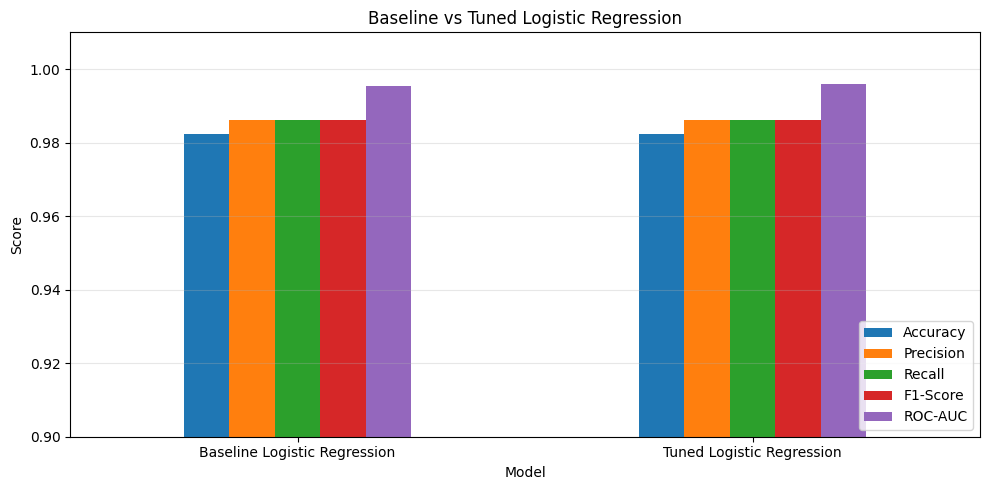

In [9]:
# Compare baseline and tuned model

comparison = pd.DataFrame([
    baseline_results,
    tuned_results
])

metrics = ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]

print("BASELINE VS TUNED MODEL")
display(comparison.round(4))

comparison.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(10, 5),
    ylim=(0.90, 1.01),
    rot=0
)

plt.title("Baseline vs Tuned Logistic Regression")
plt.ylabel("Score")
plt.xlabel("Model")
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

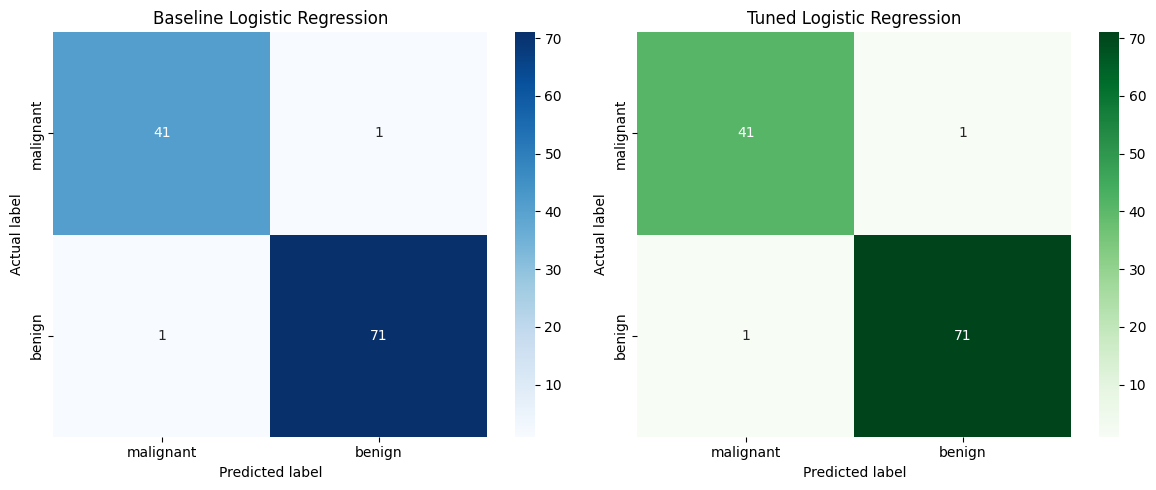

In [10]:
# Compare baseline and tuned confusion matrices

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

baseline_cm = confusion_matrix(y_test, baseline_predictions)
tuned_cm = confusion_matrix(y_test, tuned_predictions)

sns.heatmap(
    baseline_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=data.target_names,
    yticklabels=data.target_names,
    ax=axes[0]
)
axes[0].set_title("Baseline Logistic Regression")
axes[0].set_xlabel("Predicted label")
axes[0].set_ylabel("Actual label")

sns.heatmap(
    tuned_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=data.target_names,
    yticklabels=data.target_names,
    ax=axes[1]
)
axes[1].set_title("Tuned Logistic Regression")
axes[1].set_xlabel("Predicted label")
axes[1].set_ylabel("Actual label")

plt.tight_layout()
plt.show()

In [11]:
# Save baseline and tuned model metrics

comparison.to_csv(
    "model_improvement_comparison.csv",
    index=False
)

print("Comparison results saved successfully!")
display(comparison.round(4))

Comparison results saved successfully!


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Baseline Logistic Regression,0.9825,0.9861,0.9861,0.9861,0.9954
1,Tuned Logistic Regression,0.9825,0.9861,0.9861,0.9861,0.9960


## Results and Discussion

Hyperparameter tuning was performed using GridSearchCV with 5-fold stratified cross-validation. The best parameters were C = 0.1 and solver = liblinear.

The best mean cross-validation macro F1-score was 0.9811.

On the held-out test set, the baseline and tuned Logistic Regression models both achieved an accuracy of 98.25%, precision of 98.61%, recall of 98.61%, and F1-score of 98.61%.

The tuned model achieved a ROC-AUC of 99.60%, compared with 99.54% for the baseline model. This represents a small improvement in ROC-AUC, while the other reported test metrics remained unchanged.

Overall, hyperparameter tuning maintained the baseline model's classification performance and produced a slight improvement in ROC-AUC. It did not improve accuracy, precision, recall, or F1-score.

## Conclusion

This experiment compared baseline Logistic Regression with a hyperparameter-tuned version using the Breast Cancer Wisconsin dataset.

GridSearchCV selected C = 0.1 and solver = liblinear based on the mean cross-validation macro F1-score. The tuned model matched the baseline on accuracy, precision, recall, and F1-score, while achieving a slightly higher ROC-AUC.

The results demonstrate that hyperparameter tuning can produce small changes in model performance without improving every metric. Further experiments could explore alternative feature selection methods and model configurations.

The experiment provided practical experience in cross-validation, hyperparameter tuning, model evaluation, and evidence-based comparison.